# Le perceptron en pratique

Ce notebook teste la classe `Perceptron` de `perceptron.py` sur deux problèmes :
1. des données aléatoires **séparables par une droite** (le perceptron doit réussir) ;
2. le problème **XOR** (le perceptron doit échouer, c'est sa limite).

Rappel : le perceptron calcule `z = w·x + b`, prédit 1 si `z >= 0` et 0 sinon. Quand il se trompe, il corrige : `w ← w + η (y − ŷ) x` et `b ← b + η (y − ŷ)`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from perceptron import Perceptron

## 1. Données aléatoires séparables

On tire 100 points au hasard dans le plan. La classe est 1 si `x₁ + x₂ > 0`, sinon 0. Une droite sépare donc parfaitement les deux classes.

In [2]:
rng = np.random.default_rng(0)
X = rng.normal(size=(100, 2))
y = (X[:, 0] + X[:, 1] > 0).astype(int)

model = Perceptron(lr=0.1, n_epochs=15).fit(X, y)

print('Erreurs par époque :', model.errors_)
print('Poids :', model.weights, '| biais :', model.bias)
print('Exactitude :', model.score(X, y))

Erreurs par époque : [14, 10, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Poids : [0.37147757 0.40374239] | biais : 0.0
Exactitude : 1.0


Lecture : le nombre d'erreurs baisse puis tombe à 0 et y reste. Le modèle a trouvé une droite qui sépare tout. Les deux poids sont proches l'un de l'autre, ce qui retrouve la règle `x₁ + x₂`.

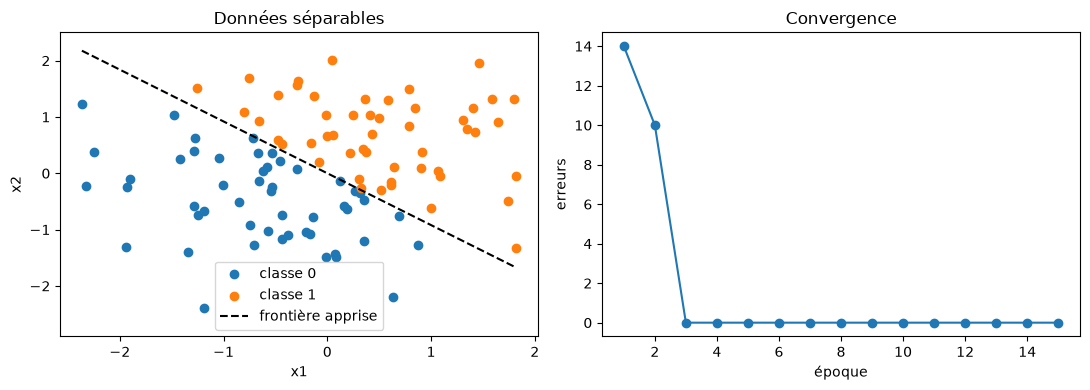

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Points et droite de décision : w1*x1 + w2*x2 + b = 0  =>  x2 = -(w1*x1 + b) / w2
ax1.scatter(X[y == 0, 0], X[y == 0, 1], label='classe 0')
ax1.scatter(X[y == 1, 0], X[y == 1, 1], label='classe 1')
x1 = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
ax1.plot(x1, -(model.weights[0] * x1 + model.bias) / model.weights[1], 'k--', label='frontière apprise')
ax1.set_ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
ax1.set_xlabel('x1'); ax1.set_ylabel('x2'); ax1.set_title('Données séparables'); ax1.legend()

ax2.plot(range(1, len(model.errors_) + 1), model.errors_, marker='o')
ax2.set_xlabel('époque'); ax2.set_ylabel('erreurs'); ax2.set_title('Convergence')
plt.tight_layout(); plt.show()

## 2. Le problème XOR

Quatre points : la classe vaut 1 quand les deux entrées sont différentes. Les points de classe 1 sont sur une diagonale du carré, ceux de classe 0 sur l'autre : aucune droite ne les sépare.

In [4]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

xor_model = Perceptron(lr=0.1, n_epochs=30).fit(X_xor, y_xor)

print('Erreurs par époque :', xor_model.errors_)
print('Prédictions :', xor_model.predict(X_xor), '| attendu :', y_xor)
print('Exactitude :', xor_model.score(X_xor, y_xor))

Erreurs par époque : [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Prédictions : [1 1 0 0] | attendu : [0 1 1 0]
Exactitude : 0.5


Lecture : le nombre d'erreurs ne tombe jamais à 0. Le perceptron corrige un point, ce qui en dérègle un autre, et ainsi de suite. C'est la limite de la frontière linéaire décrite dans la veille (question 6). Un réseau à plusieurs couches avec des activations non linéaires sait résoudre XOR.

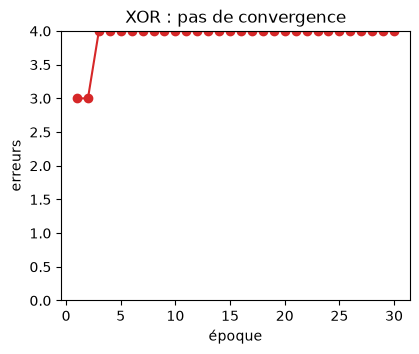

In [5]:
plt.figure(figsize=(4.5, 3.5))
plt.plot(range(1, len(xor_model.errors_) + 1), xor_model.errors_, marker='o', color='tab:red')
plt.xlabel('époque'); plt.ylabel('erreurs'); plt.title('XOR : pas de convergence')
plt.ylim(0, 4); plt.show()